# Compare electrophysiological measures of L5 cell to Kalmbach 2021 (Human L5 cells)

In [17]:
# Compare l5 cell to electrophysio measures by Kalmbach et al., 2021

import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/model_db_hay/mod'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn_dev/figures/newl5_hay/'
# import os
# os.mkdir(figpth)
from cell_builder_utils import l5_params, _get_dends, _get_pyr_soma, Cell
from hay_mechs_utils import Mechs
from plot_utils import fig_conductances, fig_compartments
from functools import partial

from hnn_core.viz import plot_cell_morphology

import pandas as pd
from scipy import signal


In [18]:
def Ih_condu_apical(gsoma, x):

    sl = 1.1
    a = 5 # 2.087
    return gsoma * (-0.8696 + a * np.exp(sl*(x/323)))

def linear_gbar(gbar_min, gbar_max, xkink, x):

    return gbar_min + (gbar_max-gbar_min) * np.min([xkink, x]) / xkink

In [19]:
# tuned model parameters (old)

# calcium behavior looks good
hay_model_params = {'soma': {'NaTs2_t': 20_400e-4, 
                                'SKv3_1': 6_930e-4,
                                'Nap_Et2': 17.2e-4,
                                'Ca_HVA': 9.92e-04*.75,
                                'Ca_LVAst': 34.3e-4*.75,
                                'SK_E2': 441e-4,
                                'Ih': 1e-4*1.1,
                                'Im': 0,
                                'K_Pst': 22.3e-4,
                                'K_Tst': 812e-4,
                                'pas': {'g': .338e-4,
                                          'e': -90}},
                        'basal': {'NaTs2_t': 20_400e-4*.1,
                                  'SKv3_1': 6_930e-4*0.1,
                                  'Ih': 5.14e-5,
                                  'pas': {'g': 1.75e-5,
                                          'e': -90}},
                        'dend': {'NaTa_t': 0.0213,
                                'SKv3_1': 0.000261,
                                'Ca_HVA': partial(linear_gbar, 2.78e-5, 2.78e-5*9, 1500),
                                'Ca_LVAst': partial(linear_gbar, 93.5e-6, 93.5e-6*4, 1500),
                                'SK_E2': 0.0012,
                                'Ih': partial(Ih_condu_apical, 1e-4),
                                'Im': 0.0000675,
                                'K_Pst': 0,
                                'K_Tst': 0,
                                'pas': {'g': 0.0000589*1.5,
                                          'e': -85}}}

## Objectives from Kalmbach paper

In [20]:
# load electrophysio from Kalmbach, 2021

df = pd.read_csv('kalmbach_2021_l5_electrophys.csv')
df['etype'].value_counts() # 1 seems to be the E-type cells



etype
2    75
1    26
3    12
Name: count, dtype: int64

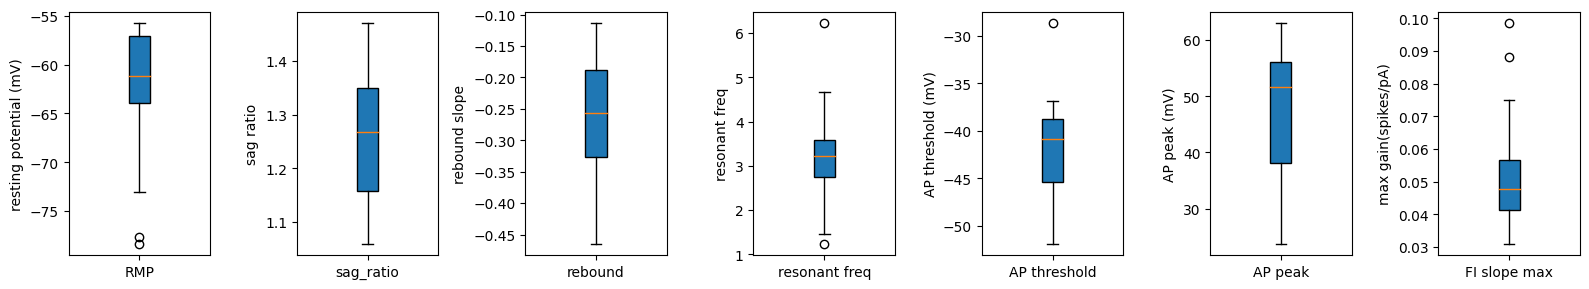

In [21]:
# l5 dataframe
l5df = df[df['etype'] == 1]

# Measures of interest:
# resting potential
# Sag_ratio
# Rebound slope
# Resonant frequency (chirp stimulus)
# AP threshold
# AP peak
# FI_slope

fig, ax = plt.subplots(1, 7, figsize=(16,3))

ax[0].boxplot(l5df['RMP'], vert=True, patch_artist=True, labels=['RMP'])
ax[0].set_ylabel('resting potential (mV)')

ax[1].boxplot(l5df['Sag_ratio'], vert=True, patch_artist=True, labels=['sag_ratio'])
ax[1].set_ylabel('sag ratio')

ax[2].boxplot(l5df['Rebound'], vert=True, patch_artist=True, labels=['rebound'])
ax[2].set_ylabel('rebound slope')

ax[3].boxplot(l5df['Fr'], vert=True, patch_artist=True, labels=['resonant freq'])
ax[3].set_ylabel('resonant freq')

ax[4].boxplot(l5df['AP_threshold'], vert=True, patch_artist=True, labels=['AP threshold'])
ax[4].set_ylabel('AP threshold (mV)')

ax[5].boxplot(l5df['AP_peak'], vert=True, patch_artist=True, labels=['AP peak'])
ax[5].set_ylabel('AP peak (mV)')

ax[6].boxplot(l5df['FI_slope_max'], vert=True, patch_artist=True, labels=['FI slope max'])
ax[6].set_ylabel('max gain(spikes/pA)')

fig.tight_layout()

## Resting membrane potential

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/model_db_hay/mod.  Aborting.


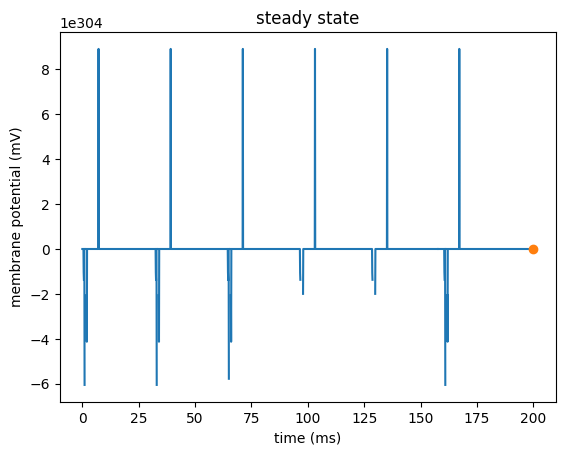

In [22]:
# Find resting membrane potential

# get paramaters
section_params, end_pts, cell_tree = l5_params()

# build sections
section_names = list(end_pts.keys())

sections = _get_dends(section_params, 'L5Pyr', section_names, end_pts)
sections['soma'] = _get_pyr_soma(section_params, 'L5Pyr', end_pts['soma'])

mech_class = Mechs(pth_mod)

# build model
hotzone = [1500, 2000]
l5pyr= Cell(sections, cell_tree, gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

t = h.Vector().record(h._ref_t)
soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize(-65 * mV)
h.continuerun(200 * ms)

soma_voltg = soma_voltg.as_numpy()


fig, ax = plt.subplots()
ax.plot(t,soma_voltg)
ax.plot(t.as_numpy()[-3],soma_voltg[-3],'o')
ax.set_xlabel('time (ms)')
ax.set_ylabel('membrane potential (mV)')
ax.set_title('steady state')


rmp = soma_voltg[-3]

## Sag ratio

Text(0.5, 1.0, 'sag ratio')

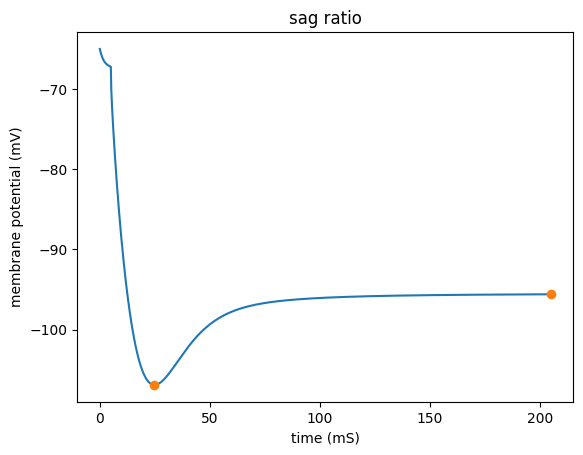

In [23]:
# Sag ratio

l5pyr= Cell(sections, cell_tree, gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

# critical freq
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 200
stim.amp = -2
clamp_current = h.Vector().record(stim._ref_i)


t = h.Vector().record(h._ref_t)
soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize(-65 * mV)
h.continuerun(205 * ms)

soma_voltg = soma_voltg.as_numpy()

peak_hyperpol = np.min(soma_voltg)
steady_state = np.min(soma_voltg[-2])

sag_ratio = peak_hyperpol/steady_state           # see Kalmbach: Voltage sag was defined as the ratio of maximum to steady-state

fig, ax = plt.subplots()
ax.plot(t, soma_voltg)
ax.set_ylabel('membrane potential (mV)')
ax.set_xlabel('time (mS)')
ax.plot(t[np.argmin(soma_voltg)], peak_hyperpol, 'o', color='tab:orange')
ax.plot(t[-2], steady_state, 'o', color='tab:orange')
ax.set_title('sag ratio')

# This looks pretty good :)


## Rebound slope

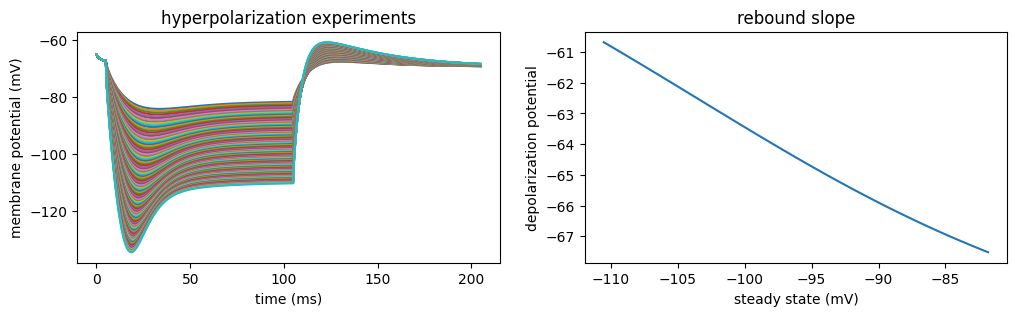

In [24]:
# Rebound slope: amplitude of rebound as a function of steady state membrane potential (during hyperpolarization)

from scipy.signal import find_peaks

l5pyr= Cell(sections, cell_tree, gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

ampl = np.linspace(-.75, -4, 100)

fig, ax = plt.subplots(1,2, figsize = (12, 3))

soma_v = np.zeros((len(ampl),len(soma_voltg)))
peak_heights = np.zeros_like(ampl)
steady_state = np.zeros_like(ampl)

for i,amp in enumerate(ampl):
    stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim.delay = 5
    stim.dur = 100
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.finitialize(-65 * mV)
    h.continuerun(205 * ms)

    steady_idx = np.argmin(np.abs(t-90))
    soma_v[i] = soma_voltg.as_numpy()

    pk = find_peaks(soma_v[i][steady_idx:], height=[-70, 50])
    if len(pk[1]) > 1:
        peak_heights[i] = pk[1]['peak_heights'][0]
    else:
        peak_heights[i] = pk[1]['peak_heights']
    
    steady_state[i] = soma_v[i][steady_idx]

    ax[0].plot(t, soma_voltg)

ax[0].set_ylabel('membrane potential (mV)')
ax[0].set_xlabel('time (ms)')
ax[0].set_title('hyperpolarization experiments')
ax[1].plot(steady_state, peak_heights)
ax[1].set_xlabel('steady state (mV)')
ax[1].set_ylabel('depolarization potential')
ax[1].set_title('rebound slope')
rebound_slope = np.polyfit(steady_state, peak_heights,1)[0]




## Action potential measures

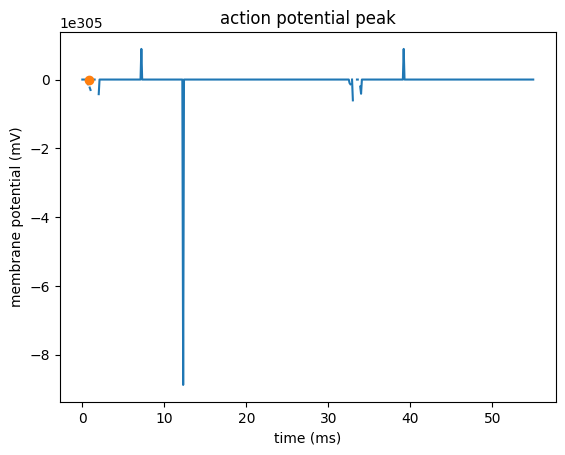

In [25]:
# AP peak

del l5pyr, stim, clamp_current, soma_voltg,

l5pyr= Cell(sections, cell_tree, gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

# critical freq
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 3
stim.amp = 3
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize(-70 * mV)
h.continuerun(55 * ms)

soma_voltg = soma_voltg.as_numpy()

ap_peak = np.max(soma_voltg)

fig, ax = plt.subplots()
ax.plot(t, soma_voltg)
ax.set_xlabel('time (ms)')
ax.set_ylabel('membrane potential (mV)')
ax.set_title('action potential peak')
ax.plot(t[np.argmax(soma_voltg)], ap_peak, 'o', color='tab:orange')


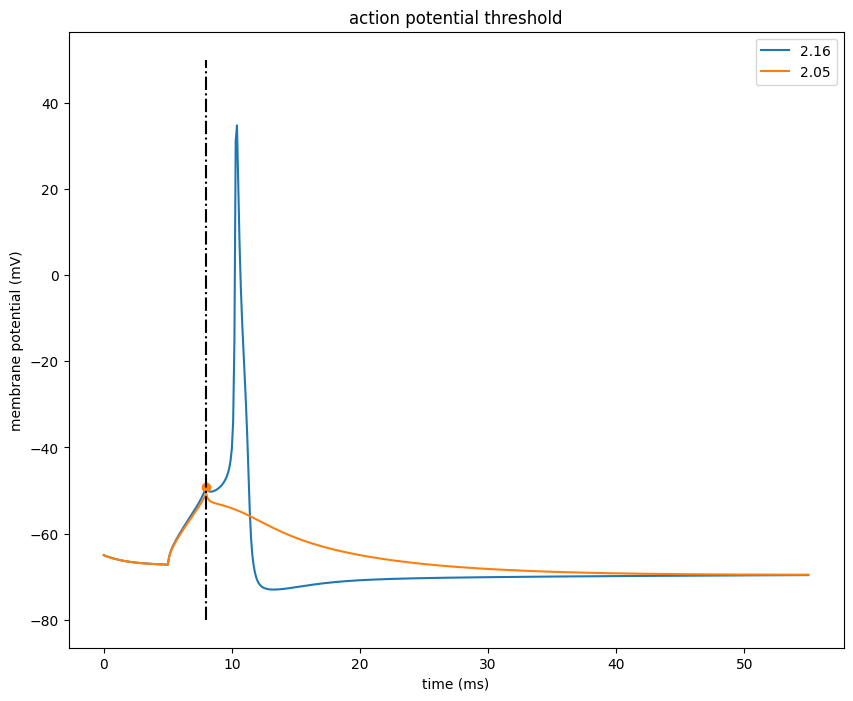

In [26]:
# AP critical threshold

# fig, ax = plt.subplots()
# ampls = np.linspace(2,0,10)

# for amp in ampls:
#     del soma_voltg

#     l5pyr= Cell(sections, cell_tree, gid=0)
#     l5pyr.build()
#     l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

#     # critical freq
#     stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
#     stim.delay = 5
#     stim.dur = 3
#     stim.amp = amp
#     clamp_current = h.Vector().record(stim._ref_i)

#     t = h.Vector().record(h._ref_t)
#     soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

#     h.celsius = 37
#     h.finitialize(-65 * mV)
#     h.continuerun(205 * ms)

#     soma_voltg = soma_voltg.as_numpy()

#     ax.plot(t, soma_voltg, label=str(amp))

# ax.legend()

fig, ax = plt.subplots(figsize=(10,8))

ampls = np.linspace(2.16,2.05,2)

line_col = ['tab:blue', 'tab:yellow']

soma_v = [None]*len(ampls)
for i,amp in enumerate(ampls):
    del soma_voltg


    l5pyr= Cell(sections, cell_tree, gid=0)
    l5pyr.build()
    l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

    # critical freq
    stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim.delay = 5
    stim.dur = 3
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.finitialize(-65 * mV)
    h.continuerun(55 * ms)

    soma_v[i] = soma_voltg.as_numpy()

    ax.plot(t, soma_voltg, label=str(amp))


ap_thresh = soma_v[0][np.argmin(np.abs(t-8))]
ax.plot(8, ap_thresh, 'o', color='tab:orange')
ax.plot(np.ones(1000,)*8,np.linspace(-80, 50,1000), 'k', linestyle='-.')
ax.set_xlabel('time (ms)')
ax.set_ylabel('membrane potential (mV)')
ax.set_title('action potential threshold')
ax.legend()



## FI slope

array([  6.6,  13.2,  19.8,  26.4,  33. ,  39.6,  46.2,  52.8,  46.2,
        52.8,  59.4,  52.8,  52.8,  46.2,  39.6,  39.6,  33. ,  33. ,
        33. ,  26.4,  19.8,  26.4,  19.8,  19.8,  26.4,  19.8,  19.8,
        13.2,  13.2,  19.8,  19.8,  13.2,  13.2,  19.8,  13.2,  13.2,
        13.2,  13.2,  19.8,  13.2,  13.2,  13.2,  13.2,   6.6,   6.6,
        13.2,   6.6,  13.2,   6.6,   6.6,   0. ,  13.2,   0. ,  13.2,
        13.2,   6.6,  13.2,   0. ,  -6.6,   6.6,  13.2, -13.2,  13.2,
         6.6,   0. ,  -6.6,   0. ,   6.6,  19.8,   0. ,   0. ,   0. ,
        13.2,   0. ,  13.2,  19.8,   0. ,  -6.6,   0. ,  19.8,   6.6,
        13.2,   0. ,  -6.6,  -6.6,  -6.6,   0. ,   6.6,  13.2])

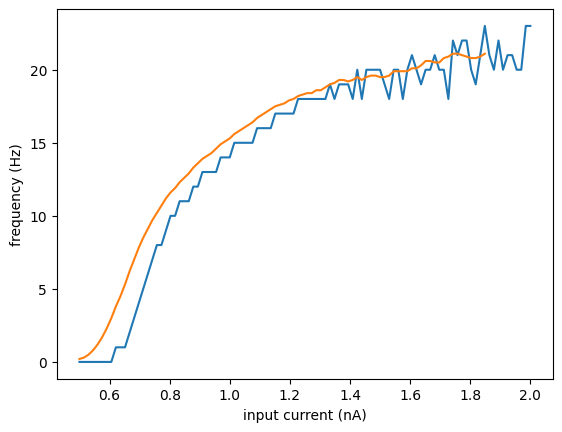

In [27]:
# FI slope
del l5pyr
ampls = np.linspace(.5,2,100)

F = np.zeros_like(ampls)
for i,amp in enumerate(ampls):

    l5pyr= Cell(sections, cell_tree, gid=0)
    l5pyr.build()
    l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

    stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
    stim.delay = 1
    stim.dur = 1000
    stim.amp = amp

    t = h.Vector().record(h._ref_t)
    soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.finitialize(-65 * mV)
    h.continuerun(1001 * ms)

    soma_voltg = soma_voltg.as_numpy()

    F[i] = len(signal.find_peaks(soma_voltg, height=30)[0])


fig, ax = plt.subplots()
ax.plot(ampls, F)
ax.set_ylabel('frequency (Hz)')
ax.set_xlabel('input current (nA)')

FI_slope = np.diff(np.array(F))/np.diff(ampls)[0]

ampl_diff = np.diff(ampls)[0]

smooth_F = np.zeros((len(F)-10,))
for i,f in enumerate(F[:-10]):
    smooth_F[i] = np.mean(F[i:i+10])

ax.plot(ampls[:-10], smooth_F)

# slope: difference in frequency per nA step
smooth_slope = np.diff(smooth_F)/np.diff(ampls[:-10])
pA = 0.001 # nA (convert nA to pA)
smooth_slope

## Resonance in response to chirp stimulus

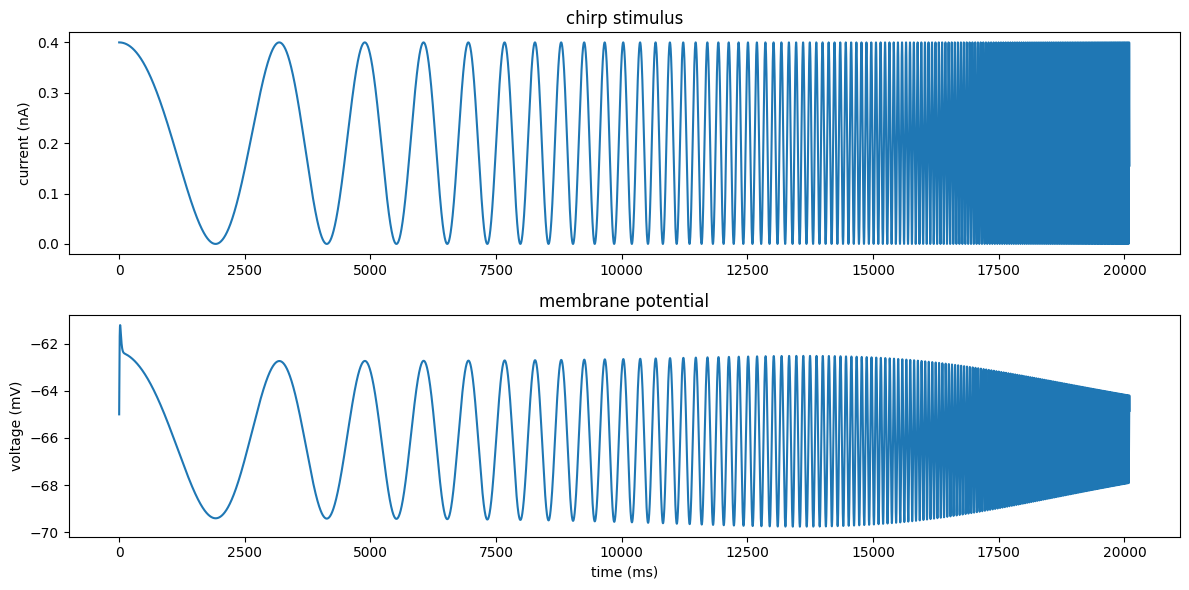

In [28]:
# Chirp stimulus


from scipy.signal import chirp
l5pyr= Cell(sections, cell_tree, gid=0)
l5pyr.build()
l5pyr = mech_class.add_mechs(l5pyr, hay_model_params, hotzone=hotzone)

# Define simulation parameters
h.tstop = 20_100  # Simulation duration in ms
h.dt = 0.1    # Time step

# Create a chirp stimulus (linear frequency sweep)
t_chirp = np.arange(0, h.tstop, h.dt)  # Time vector

# Kalmbach et al: linear increase from 1-15 Hz over
f0 = 0.2  # Initial frequency in Hz
f1 = 40  # Final frequency in Hz
A = .2  # Amplitude of the chirp in nA - adjusted to achieve a voltage deflection of ~10mV peak to peak 

# Chirp signal: I(t) = A * sin(2 * pi * f(t) * t)
#f_t = f0 + (f1 - f0) * t_chirp / h.tstop  # Linearly increasing frequency
#chirp_signal = A * np.sin(2 * np.pi * f_t * t_chirp/1000)  + .2# Convert ms to seconds

# logarithmic chirp
chirp_signal = A * chirp(t_chirp/1000, f0, 20, f1, method='log') + 0.2

# set up clamp
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 0
stim.dur = h.tstop+stim.delay
stim.amp = 0  # We'll use Vector.play() to set the amplitude
# Apply the chirp stimulus using a Vector and play()
stim_vec = h.Vector(chirp_signal)
t = np.arange(0, h.tstop, h.dt)
time_vec = h.Vector(t)
stim_vec.play(stim._ref_amp, time_vec, 1)

# Record membrane potential
v_rec = h.Vector()
v_rec.record(l5pyr._nrn_sections['soma'](0.5)._ref_v)
t_rec = h.Vector().record(h._ref_t)
# Run the simulation
h.finitialize(-65)  # Initialize membrane potential
h.continuerun(h.tstop)

# Plot results

fig, ax = plt.subplots(2,1, figsize=(12,6))

ax[0].plot(t, chirp_signal)
ax[0].set_ylabel('current (nA)')
ax[0].set_title('chirp stimulus')

ax[1].plot(t_rec-stim.delay, v_rec.as_numpy(), label='Membrane Potential')
ax[1].set_xlabel('time (ms)')
ax[1].set_ylabel('voltage (mV)')
ax[1].set_title('membrane potential')
fig.tight_layout()


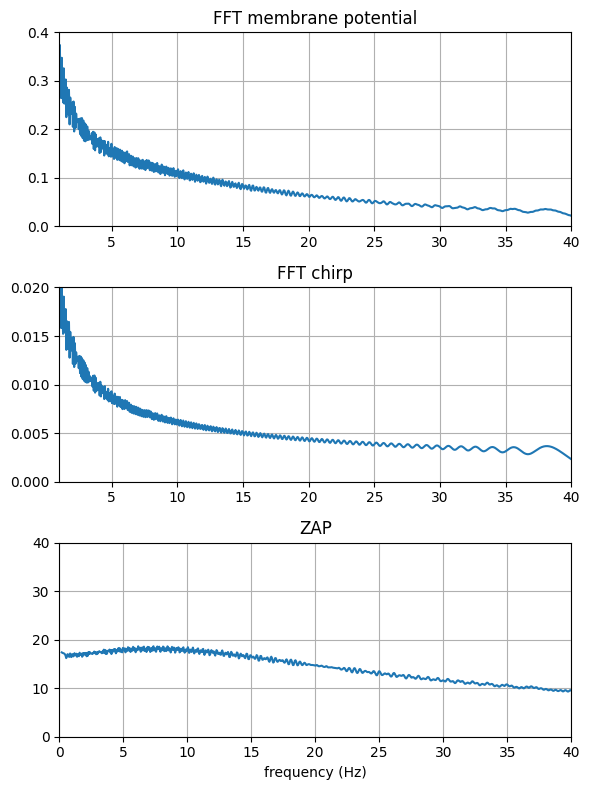

In [29]:
# Kalmbach: impedance amplitude is the ratio between FFT of response and FFT of chirp

from scipy.fft import fft, fftfreq

from scipy.signal import windows
gauss_win = windows.gaussian(len(chirp_signal), len(chirp_signal)/1.5)

N = len(v_rec)
T = h.dt/1000
freq = fftfreq(N, T)[:N//2]
lowf = np.argmin(np.abs(freq-0.2))

fft_membr = fft(v_rec.as_numpy()[1:])
fft_chirp = fft(chirp_signal)

impedance = fft_membr/fft_chirp
zap = np.abs(impedance)
zap = zap[:N//2]

fig, ax = plt.subplots(3,1,figsize=(6,8))
fft_membr =  2.0/N * np.abs(fft_membr[:N//2])
ax[0].plot(freq[lowf:], fft_membr[lowf:])
ax[0].set_xlim([1, 40])
ax[0].set_ylim([0, .4])
ax[0].grid()
ax[0].set_title('FFT membrane potential')

fft_chirp = 2.0/N * np.abs(fft_chirp[:N//2])
ax[1].plot(freq[lowf:], fft_chirp[lowf:])
ax[1].set_title('FFT chirp')
ax[1].set_xlim([1, 40])
ax[1].set_ylim([0, .02])

ax[1].grid()

ax[2].plot(freq[lowf:], zap[lowf:])
ax[2].set_xlabel('frequency (Hz)')
ax[2].set_title('ZAP')
ax[2].set_xlim([0, 40])
ax[2].set_ylim([0, 40])

ax[2].grid()
fig.tight_layout()

6.517380510544723

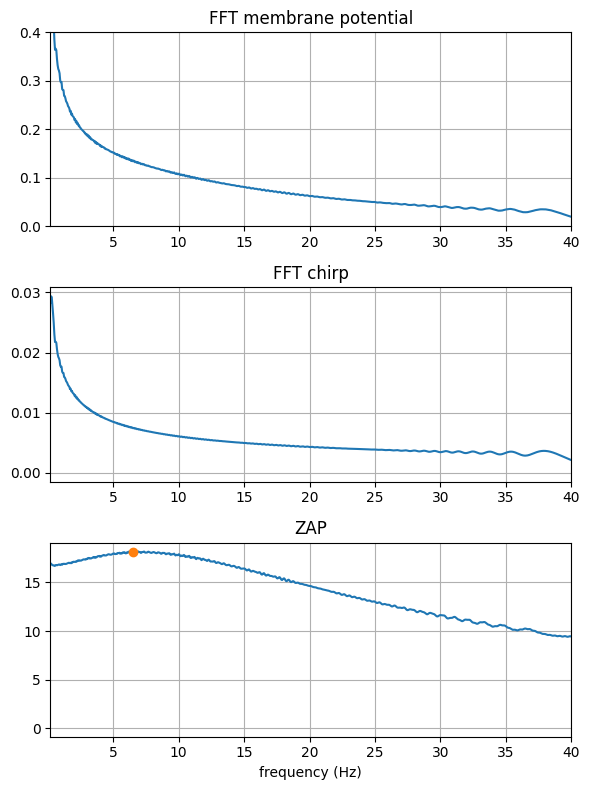

In [30]:
# smooth with moving average

chirp_smooth = np.zeros(fft_chirp.shape[0]-10)
vrec_smooth = np.zeros(fft_membr.shape[0]-10)
zap_smooth = np.zeros(zap.shape[0]-10)

for c in range(len(fft_chirp)-10):
    chirp_smooth[c] = np.mean(fft_chirp[c:c+10])
    vrec_smooth[c] = np.mean(fft_membr[c:c+10])
    zap_smooth[c] = np.mean(zap[c:c+10])
    
fig, ax = plt.subplots(3,1,figsize=(6,8))
ax[0].plot(freq[lowf:-10], vrec_smooth[lowf:])
ax[0].set_xlim([.2, 40])
ax[0].set_ylim([0, .4])
ax[0].grid()
ax[0].set_title('FFT membrane potential')

fft_chirp = 2.0/N * np.abs(fft_chirp[:N//2])
ax[1].plot(freq[lowf:-10], chirp_smooth[lowf:])
ax[1].set_title('FFT chirp')
ax[1].set_xlim([.2, 40])
#ax[1].set_ylim([0, .02])

ax[1].grid()

ax[2].plot(freq[lowf:-10], zap_smooth[lowf:])
res_freq = freq[np.argmax(zap_smooth[lowf:])-lowf]

ax[2].plot(res_freq,zap_smooth[np.argmax(zap_smooth[lowf:])-lowf], 'o', color='tab:orange')
ax[2].set_xlabel('frequency (Hz)')
ax[2].set_title('ZAP')
ax[2].set_xlim([.2, 40])
#ax[2].set_ylim([0, 10])
#
ax[2].grid()
fig.tight_layout()

res_freq

## Summarize all measures

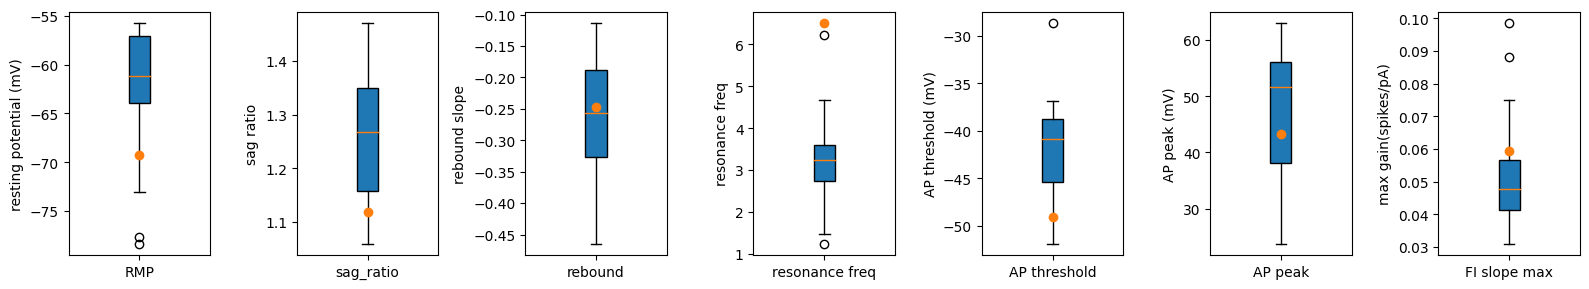

In [31]:
fig, ax = plt.subplots(1, 7, figsize=(16,3))

ax[0].boxplot(l5df['RMP'], vert=True, patch_artist=True, labels=['RMP'])
ax[0].plot(1, rmp, 'o', color='tab:orange')
ax[0].set_ylabel('resting potential (mV)')

ax[1].boxplot(l5df['Sag_ratio'], vert=True, patch_artist=True, labels=['sag_ratio'])
ax[1].plot(1, sag_ratio, 'o', color='tab:orange')

ax[1].set_ylabel('sag ratio')

ax[2].boxplot(l5df['Rebound'], vert=True, patch_artist=True, labels=['rebound'])
ax[2].plot(1,rebound_slope, 'o', color='tab:orange')
ax[2].set_ylabel('rebound slope')

ax[3].boxplot(l5df['Fr'], vert=True, patch_artist=True, labels=['resonance freq'])
ax[3].plot(1,res_freq, 'o', color='tab:orange')
ax[3].set_ylabel('resonance freq')

ax[4].boxplot(l5df['AP_threshold'], vert=True, patch_artist=True, labels=['AP threshold'])
ax[4].set_ylabel('AP threshold (mV)')
ax[4].plot(1, ap_thresh, 'o', color='tab:orange')

ax[5].boxplot(l5df['AP_peak'], vert=True, patch_artist=True, labels=['AP peak'])
ax[5].set_ylabel('AP peak (mV)')
ax[5].plot(1, ap_peak, 'o', color='tab:orange')

ax[6].boxplot(l5df['FI_slope_max'], vert=True, patch_artist=True, labels=['FI slope max'])
ax[6].set_ylabel('max gain(spikes/pA)')
ax[6].plot(1, max(smooth_slope)*pA, 'o', color='tab:orange')

fig.tight_layout()